## Import

In [1]:
import pandas as pd
import numpy as np
import json
import pickle
import torch

from pathlib import Path
from pykeen.pipeline import pipeline
from pykeen.triples import TriplesFactory

## Load KG TRAIN

In [2]:
KG_PATH = Path("../outputs/kg_train.tsv")

kg_df = pd.read_csv(
    KG_PATH,
    sep="\t"
)

print("KG shape:", kg_df.shape)

assert kg_df.shape[0] == 448000
assert "has_dev_status" not in kg_df["relation"].values

print("✅ KG = TRAIN 80% saja")
print("✅ dev_status tidak ada dalam KG")

KG shape: (448000, 3)
✅ KG = TRAIN 80% saja
✅ dev_status tidak ada dalam KG


## Buat TriplesFactory

In [3]:
triples = kg_df[
    ["head", "relation", "tail"]
].values

tf_full = TriplesFactory.from_labeled_triples(
    triples
)

print("Entities :", tf_full.num_entities)
print("Relations:", tf_full.num_relations)
print("Triples  :", tf_full.num_triples)

Entities : 64111
Relations: 7
Triples  : 448000


## Train Final TransE

In [4]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ CUDA tidak tersedia. Training akan gagal jika dipaksa menggunakan cuda.")

CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [5]:
from pykeen.models import TransE
from pykeen.training import SLCWATrainingLoop
from pykeen.losses import MarginRankingLoss
from pykeen.sampling import BasicNegativeSampler
from torch.optim import Adam

print("Training Final TransE...")

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =========================
# 1. Buat model TransE
# =========================
model_full = TransE(
    triples_factory=tf_full,
    embedding_dim=100,
    loss=MarginRankingLoss(margin=1.0),
)

model_full = model_full.to(device)

# =========================
# 2. Optimizer
# =========================
optimizer = Adam(
    params=model_full.get_grad_params()
)

# =========================
# 3. Training loop
# =========================
training_loop = SLCWATrainingLoop(
    model=model_full,
    triples_factory=tf_full,
    optimizer=optimizer,
    negative_sampler=BasicNegativeSampler,
)

# =========================
# 4. Training
# =========================
losses = training_loop.train(
    triples_factory=tf_full,
    num_epochs=100,
    batch_size=256,
)

print("✅ Final TransE selesai.")
print("Device:", device)
print("Training triples:", tf_full.num_triples)

No random seed is specified. This may lead to non-reproducible results.


Training Final TransE...


Training epochs on cuda:0:   0%|          | 0/100 [00:00<?, ?epoch/s]

Training batches on cuda:0:   0%|          | 0.00/1.75k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.75k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.75k [00:00<?, ?batch/s]

... (94 outputs left out)

Training batches on cuda:0:   0%|          | 0.00/1.75k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.75k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.75k [00:00<?, ?batch/s]

✅ Final TransE selesai.
Device: cuda
Training triples: 448000


## Simpan Final TransE

In [6]:
MODEL_DIR = Path("../models/transe")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "transe_model_full_train.pkl"

with open(MODEL_PATH, "wb") as f:
    pickle.dump(
        model_full,
        f
    )

print("✅ Final TransE disimpan:")
print(MODEL_PATH)

✅ Final TransE disimpan:
..\models\transe\transe_model_full_train.pkl


## Ambil embedding

In [7]:
model = model_full

entity_embeddings = (
    model.entity_representations[0]()
    .detach()
    .cpu()
    .numpy()
)

relation_embeddings = (
    model.relation_representations[0]()
    .detach()
    .cpu()
    .numpy()
)

entity_to_id = tf_full.entity_to_id
relation_to_id = tf_full.relation_to_id

print("Entity embedding :", entity_embeddings.shape)
print("Relation embedding:", relation_embeddings.shape)

Entity embedding : (64111, 100)
Relation embedding: (7, 100)


## Load TRAIN dan TEST

In [8]:
train_df = pd.read_csv("../data/processed/train.csv")
test_df = pd.read_csv("../data/processed/test.csv")

print("TRAIN:", train_df.shape)
print("TEST :", test_df.shape)

TRAIN: (64000, 8)
TEST : (16000, 8)


## Tentukan feature

In [9]:
FEATURE_COLUMNS = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

NUMERIC_FEATURES = [
    "weight",
    "height",
    "age"
]

CATEGORICAL_FEATURES = [
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

RELATION_MAP = {
    "weight": "has_weight",
    "height": "has_height",
    "age": "has_age",
    "gross_motor": "has_gross_motor",
    "fine_motor_adaptive": "has_fine_motor_adaptive",
    "language": "has_language",
    "personal_social": "has_personal_social"
}

assert "dev_status" not in FEATURE_COLUMNS

print("✅ dev_status bukan feature KGE")

✅ dev_status bukan feature KGE


## Siapkan numeric entity dari TRAIN

In [10]:
numeric_entity_values = {}

for feature in NUMERIC_FEATURES:

    prefix = f"{feature}_"
    values = []

    for entity in entity_to_id:

        if entity.startswith(prefix):

            try:
                value = float(entity[len(prefix):])
                values.append((value, entity))
            except ValueError:
                pass

    values.sort(key=lambda x: x[0])

    numeric_entity_values[feature] = values

    print(
        feature,
        "TRAIN entities:",
        len(values)
    )

weight TRAIN entities: 18
height TRAIN entities: 71
age TRAIN entities: 6


## Fungsi lookup entity

In [11]:

def format_value(value):
    if pd.isna(value):
        return "unknown"

    if isinstance(value, (int, np.integer)):
        return str(value)

    if isinstance(value, (float, np.floating)):
        return f"{value:.6f}".rstrip("0").rstrip(".")

    return str(value).strip().lower().replace(" ", "_")


def get_tail_entity(feature, value):

    # CATEGORICAL
    if feature in CATEGORICAL_FEATURES:

        entity = f"{feature}_{format_value(value)}"

        if entity not in entity_to_id:
            raise ValueError(
                f"Categorical entity tidak ditemukan di TRAIN: {entity}"
            )

        return entity

    # NUMERIC
    numeric_value = float(value)

    candidates = numeric_entity_values[feature]

    if not candidates:
        raise ValueError(
            f"Tidak ada numeric entity TRAIN untuk {feature}"
        )

    # Exact match
    exact_entity = f"{feature}_{format_value(numeric_value)}"

    if exact_entity in entity_to_id:
        return exact_entity

    # Nearest value dari TRAIN
    _, nearest_entity = min(
        candidates,
        key=lambda x: abs(x[0] - numeric_value)
    )

    return nearest_entity


## Fungsi representasi KGE

In [12]:
def get_kge_embedding(row):

    vectors = []

    for feature in FEATURE_COLUMNS:

        relation = RELATION_MAP[feature]

        tail_entity = get_tail_entity(
            feature,
            row[feature]
        )

        tail_id = entity_to_id[tail_entity]
        relation_id = relation_to_id[relation]

        tail_vector = entity_embeddings[tail_id]
        relation_vector = relation_embeddings[relation_id]

        child_vector = (
            tail_vector - relation_vector
        )

        vectors.append(child_vector)

    return np.mean(
        vectors,
        axis=0
    )

## Test satu row

In [13]:
test_vector = get_kge_embedding(
    train_df.iloc[0]
)

print("Shape:", test_vector.shape)
print(test_vector[:10])

assert test_vector.shape == (100,)

Shape: (100,)
[-0.00967363 -0.04762232  0.0152862   0.00944061 -0.01637721  0.0515273
 -0.04590474  0.07625543  0.04891567  0.01008769]


## Generate KGE TRAIN

In [14]:
train_kge = np.vstack(
    train_df.apply(
        get_kge_embedding,
        axis=1
    ).values
)

print("TRAIN KGE:", train_kge.shape)

assert train_kge.shape == (64000, 100)

TRAIN KGE: (64000, 100)


## Generate KGE TEST

In [15]:
test_kge = np.vstack(
    test_df.apply(
        get_kge_embedding,
        axis=1
    ).values
)

print("TEST KGE:", test_kge.shape)

assert test_kge.shape == (16000, 100)

TEST KGE: (16000, 100)


In [25]:
print("Jumlah elemen embedding TRAIN:", f"{train_kge.size:,}".replace(",", "."))
print("Jumlah elemen embedding TEST :", f"{test_kge.size:,}".replace(",", "."))

Jumlah elemen embedding TRAIN: 6.400.000
Jumlah elemen embedding TEST : 1.600.000


## Visualisasi

Variasi yang dijelaskan:
PC1 : 5.32%
PC2 : 5.02%
PC1 + PC2 : 10.33%
Jumlah PC untuk mencapai 80%: 28
Jumlah PC untuk mencapai 90%: 44


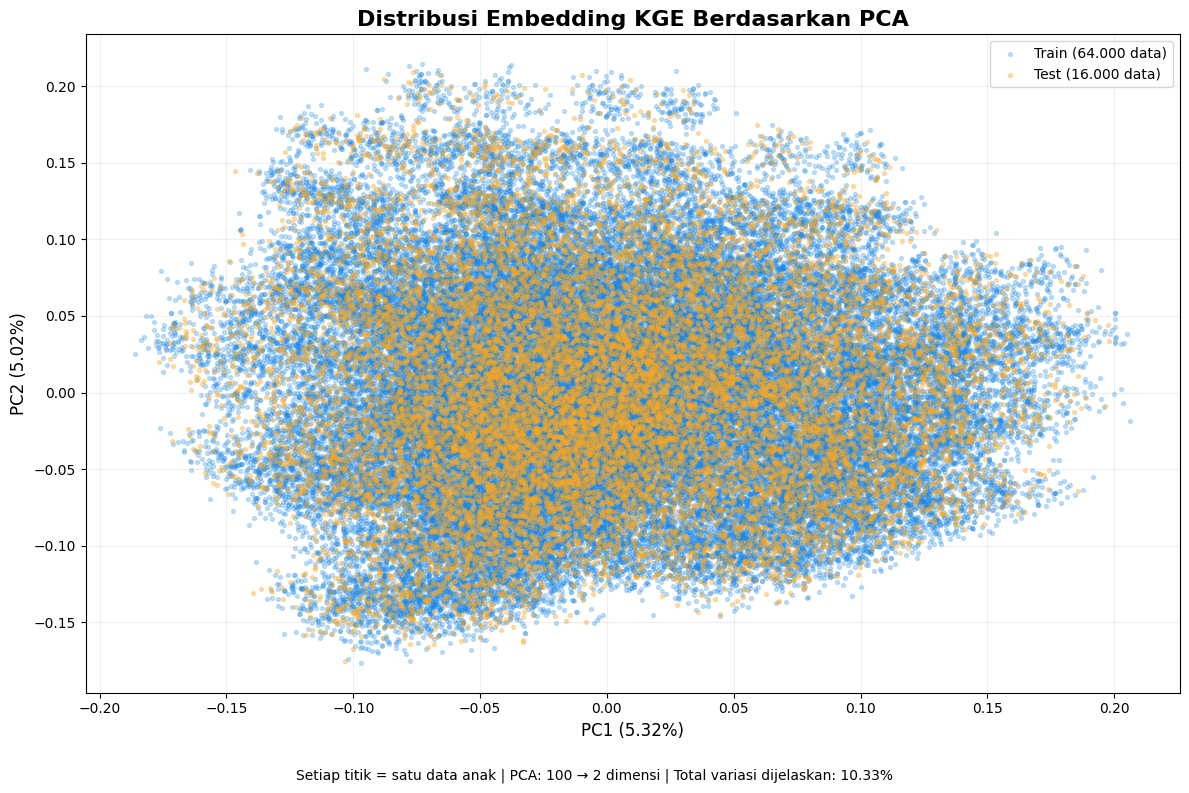

In [19]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from pathlib import Path

# PCA dilakukan berdasarkan data TRAIN
# Seluruh 100 komponen dihitung untuk menganalisis variasi
pca = PCA(n_components=None)

train_pca_all = pca.fit_transform(train_kge)
test_pca_all = pca.transform(test_kge)

# Menghitung variasi setiap komponen
explained_variance = pca.explained_variance_ratio_ * 100
cumulative_variance = np.cumsum(explained_variance)

# Menentukan jumlah komponen untuk mencapai variasi tertentu
n_80 = np.argmax(cumulative_variance >= 80) + 1
n_90 = np.argmax(cumulative_variance >= 90) + 1

print("Variasi yang dijelaskan:")
print(f"PC1 : {explained_variance[0]:.2f}%")
print(f"PC2 : {explained_variance[1]:.2f}%")
print(f"PC1 + PC2 : {cumulative_variance[1]:.2f}%")
print(f"Jumlah PC untuk mencapai 80%: {n_80}")
print(f"Jumlah PC untuk mencapai 90%: {n_90}")

# Visualisasi PC1 dan PC2
fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    train_pca_all[:, 0],
    train_pca_all[:, 1],
    s=8,
    alpha=0.25,
    color="#1E88E5",
    label="Train (64.000 data)"
)

ax.scatter(
    test_pca_all[:, 0],
    test_pca_all[:, 1],
    s=8,
    alpha=0.35,
    color="#F9A825",
    label="Test (16.000 data)"
)

ax.set_title(
    "Distribusi Embedding KGE Berdasarkan PCA",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel(
    f"PC1 ({explained_variance[0]:.2f}%)",
    fontsize=12
)

ax.set_ylabel(
    f"PC2 ({explained_variance[1]:.2f}%)",
    fontsize=12
)

ax.legend()
ax.grid(alpha=0.2)

fig.text(
    0.5, 0.015,
    "Setiap titik = satu data anak | PCA: 100 → 2 dimensi | "
    f"Total variasi dijelaskan: {cumulative_variance[1]:.2f}%",
    ha="center",
    va="bottom",
    fontsize=10
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

FIGURE_DIR = Path("../outputs/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

output_path = FIGURE_DIR / "distribusi_embedding_kge_pca.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

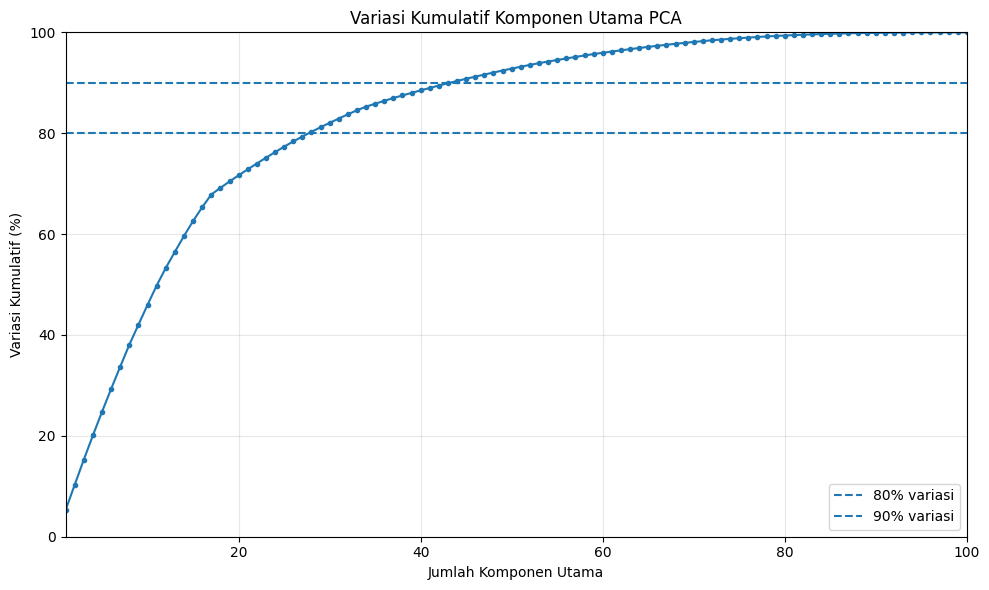

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    range(1, 101),
    cumulative_variance,
    marker="o",
    markersize=3
)

ax.axhline(
    y=80,
    linestyle="--",
    label="80% variasi"
)

ax.axhline(
    y=90,
    linestyle="--",
    label="90% variasi"
)

ax.set_title(
    "Variasi Kumulatif Komponen Utama PCA"
)

ax.set_xlabel("Jumlah Komponen Utama")
ax.set_ylabel("Variasi Kumulatif (%)")

ax.set_xlim(1, 100)
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [24]:
# Persentase variasi setiap PC
explained_variance = pca.explained_variance_ratio_ * 100

# Persentase variasi kumulatif
cumulative_variance = np.cumsum(explained_variance)

print("Distribusi Variasi PCA:")

for i in range(len(explained_variance)):
    print(
        f"PC{i+1:02d}: {explained_variance[i]:.4f}% "
        f"| Kumulatif: {cumulative_variance[i]:.4f}%"
    )

print(f"\nTotal variasi PC1-PC100: {cumulative_variance[-1]:.4f}%")

Distribusi Variasi PCA:
PC01: 5.3151% | Kumulatif: 5.3151%
PC02: 5.0178% | Kumulatif: 10.3329%
PC03: 4.9725% | Kumulatif: 15.3054%
PC04: 4.8164% | Kumulatif: 20.1218%
PC05: 4.6701% | Kumulatif: 24.7918%
PC06: 4.5264% | Kumulatif: 29.3182%
PC07: 4.4275% | Kumulatif: 33.7457%
PC08: 4.3309% | Kumulatif: 38.0767%
PC09: 3.9798% | Kumulatif: 42.0565%
PC10: 3.9290% | Kumulatif: 45.9855%
PC11: 3.8202% | Kumulatif: 49.8056%
PC12: 3.4853% | Kumulatif: 53.2910%
PC13: 3.1956% | Kumulatif: 56.4865%
PC14: 3.1354% | Kumulatif: 59.6220%
PC15: 2.9732% | Kumulatif: 62.5952%
PC16: 2.7249% | Kumulatif: 65.3201%
PC17: 2.5274% | Kumulatif: 67.8475%
PC18: 1.3102% | Kumulatif: 69.1577%
PC19: 1.2754% | Kumulatif: 70.4331%
PC20: 1.2106% | Kumulatif: 71.6437%
PC21: 1.1917% | Kumulatif: 72.8354%
PC22: 1.1554% | Kumulatif: 73.9908%
PC23: 1.1407% | Kumulatif: 75.1316%
PC24: 1.1069% | Kumulatif: 76.2385%
PC25: 1.0866% | Kumulatif: 77.3250%
PC26: 1.0335% | Kumulatif: 78.3586%
PC27: 0.9761% | Kumulatif: 79.3346%
PC28:

In [22]:
# Menghitung standar deviasi setiap dimensi KGE
kge_std = np.std(train_kge, axis=0)

print("Statistik standar deviasi 100 dimensi KGE:")
print(f"Minimum : {kge_std.min():.6f}")
print(f"Maksimum: {kge_std.max():.6f}")
print(f"Rata-rata: {kge_std.mean():.6f}")
print(f"Median  : {np.median(kge_std):.6f}")

Statistik standar deviasi 100 dimensi KGE:
Minimum : 0.026267
Maksimum: 0.034089
Rata-rata: 0.030674
Median  : 0.030843


## Simpan KGE

In [17]:
OUTPUT_DIR = Path("../outputs/kge_features")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

kge_columns = [
    f"kge_{i+1}"
    for i in range(100)
]

train_kge_df = pd.DataFrame(
    train_kge,
    columns=kge_columns
)

test_kge_df = pd.DataFrame(
    test_kge,
    columns=kge_columns
)

train_kge_df.to_csv(
    OUTPUT_DIR / "train_kge_embeddings.csv",
    index=False
)

test_kge_df.to_csv(
    OUTPUT_DIR / "test_kge_embeddings.csv",
    index=False
)

print("✅ TRAIN KGE tersimpan")
print("✅ TEST KGE tersimpan")

✅ TRAIN KGE tersimpan
✅ TEST KGE tersimpan


## Validasi leakage

In [18]:
print("=" * 60)
print("CHECKPOINT 5B — FINAL CHECK")
print("=" * 60)

assert "dev_status" not in FEATURE_COLUMNS
assert "has_dev_status" not in kg_df["relation"].values

assert train_kge.shape == (64000, 100)
assert test_kge.shape == (16000, 100)

print("✅ TRAIN = 64.000")
print("✅ TEST = 16.000")
print("✅ KGE dimension = 100")
print("✅ dev_status tidak digunakan")
print("✅ TransE hanya dilatih menggunakan TRAIN")
print("✅ TEST hanya digunakan untuk memperoleh representasi")
print("✅ Tidak ada training TransE menggunakan TEST")
print("✅ Checkpoint 5B selesai")

CHECKPOINT 5B — FINAL CHECK
✅ TRAIN = 64.000
✅ TEST = 16.000
✅ KGE dimension = 100
✅ dev_status tidak digunakan
✅ TransE hanya dilatih menggunakan TRAIN
✅ TEST hanya digunakan untuk memperoleh representasi
✅ Tidak ada training TransE menggunakan TEST
✅ Checkpoint 5B selesai
